In [13]:
import pandas as pd
import sys

sys.path.insert(0, "../src")

import manadsanalys
import viz_manad

import importlib

importlib.reload(viz_manad)


df = pd.read_csv("../data/ecommerce_sales.csv")   # Läs in försäljningsdata från CSV-filen

df_manad = df.copy()   # Skapa en kopia för månadsanalysen utan att ändra originaldata

df_manad["date"] = pd.to_datetime(df_manad["date"])   # Omvandla datumkolumnen från sträng till datetime

df_manad["månad"] = df_manad["date"].dt.month   # Skapa en ny kolumn med månadsnummer (1–12) från datumet

# Månadsanalys – Januari till Juni 2024

Månadsanalysen syftar till att undersöka **försäljningsutvecklingen** under första halvåret 2024 och identifiera eventuella förändringar och avvikelser.

Analysen utgår från den totala omsättningen och dess fördelning mellan produktkategorier och städer. Därefter fördjupas analysen med hjälp av nyckeltal som försäljningsvolym, antal order och genomsnittligt ordervärde.

In [6]:
#omsattning = manadsanalys.månadsförsäljning(df_manad)

#viz_manad.visa_manadsforsaljning(omsattning)

In [4]:
# Beräkna omsättningen per kategori och stad
#omsattning_kategori = manadsanalys.månadsförsäljning_kategori(df_manad)
#omsattning_stad = manadsanalys.månadsförsäljning_stad(df_manad)

# Visa båda diagrammen i samma figur
#viz_manad.visa_kategori_och_stad(omsattning_kategori, omsattning_stad)

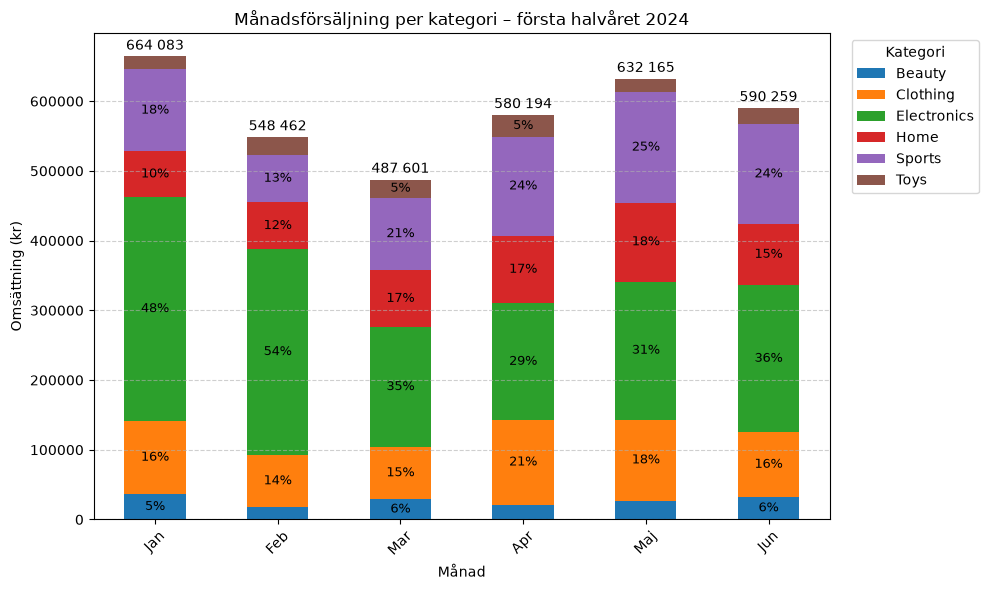

In [11]:
omsattning_kategori = manadsanalys.månadsförsäljning_kategori(df_manad)

viz_manad.visa_manadsforsaljning_kategori(omsattning_kategori)

*Figur 1. Månadsomsättning fördelad per produktkategori, januari–juni 2024.*

# Observationer

Omsättningen minskar från januari till mars, med den största nedgången mellan januari och februari (−17,4 %). Under denna period är kategorifördelningen relativt stabil. Mellan februari och mars minskar omsättningen ytterligare (−11,1 %), samtidigt som **Electronics andel sjunker kraftigt, från cirka 54 % till 35 %.**

Detta tyder på olika bakomliggande försäljningsmönster och motiverar en fördjupad analys av både försäljningsvolym och produktmix.

**Geografisk fördelning:** Försäljningsutvecklingen uppvisar ett relativt likartat mönster mellan städerna, där omsättningsförändringarna i huvudsak följer samma trend. Ingen enskild stad framstår som en tydlig förklaring till variationerna i den totala omsättningen.

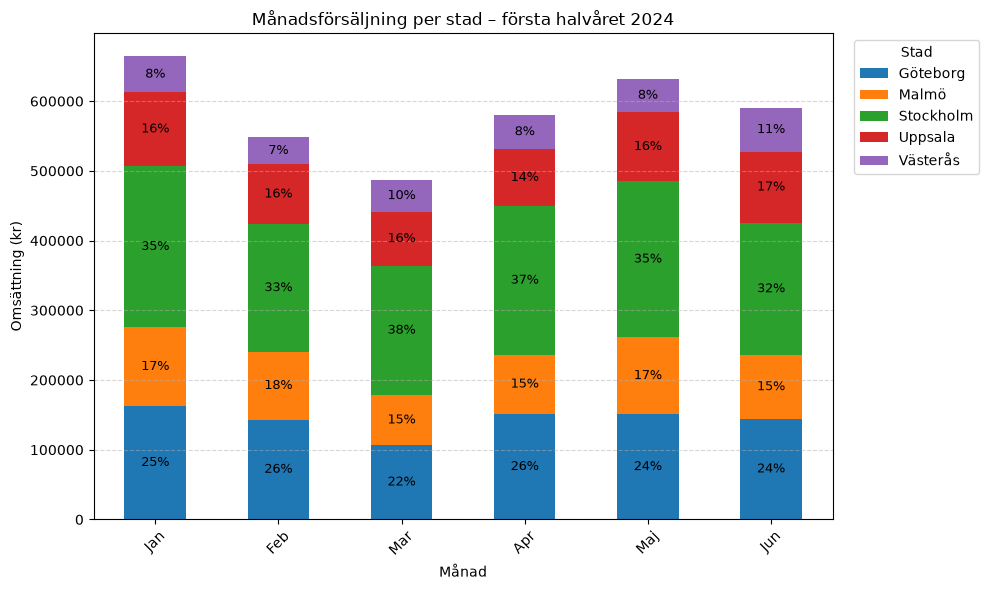

In [18]:
omsattning_stad = manadsanalys.månadsförsäljning_stad(df_manad)
viz_manad.visa_manadsforsaljning_stad(omsattning_stad)

*Figur 2. Månadsomsättning fördelad per stad, januari–juni 2024.*

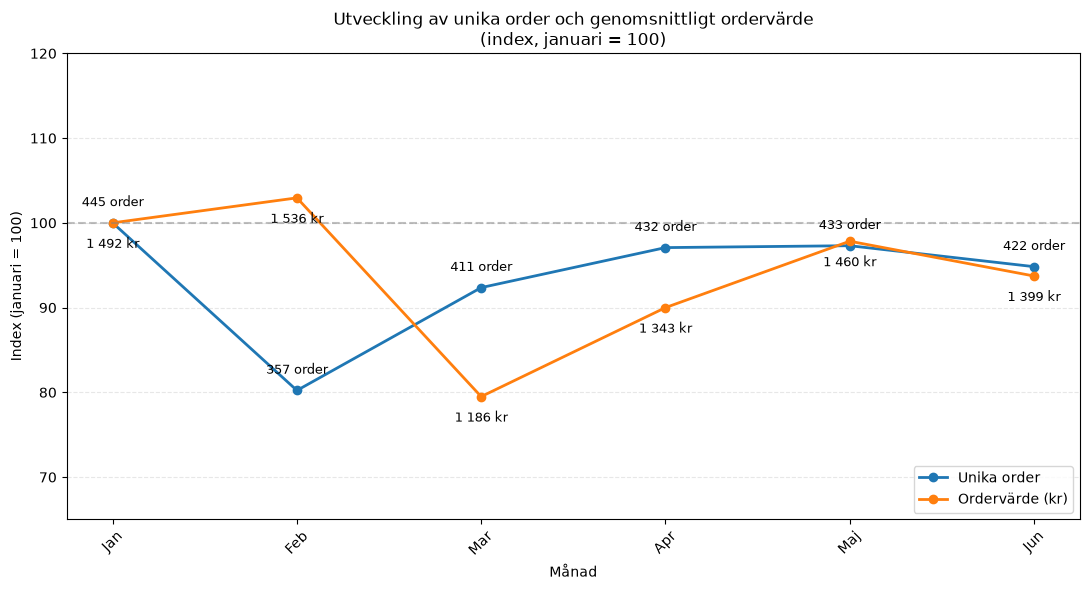

In [14]:
antal_order = manadsanalys.antal_unika_order_månad(df_manad)
ordervarde = manadsanalys.ordervärde_medel_månad(df_manad)

viz_manad.visa_orderutveckling_index(antal_order, ordervarde)

*Figur 3. Utveckling av antal unika order och genomsnittligt ordervärde, januari–juni 2024 (index, januari = 100).*

# Observationer

Omsättningsnedgången från januari till februari sammanfaller med en minskning av antalet unika order med cirka 20 %, medan det genomsnittliga ordervärdet är relativt oförändrat. Mellan februari och mars ökar däremot antalet order med cirka 15 %, samtidigt som det genomsnittliga ordervärdet sjunker med cirka 23 %.

Detta tyder på två olika försäljningsmönster: den första nedgången är främst kopplad till färre beställningar, medan den andra sammanfaller med ett lägre värde per beställning.

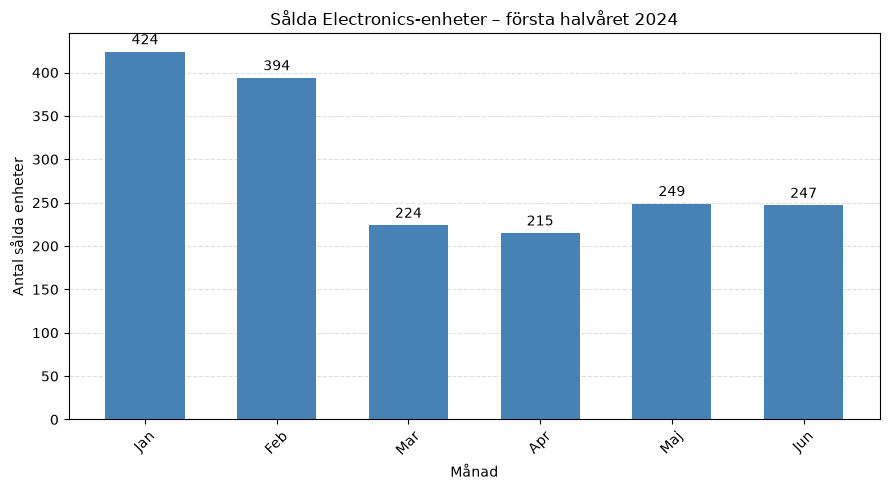

In [15]:
electronics_enheter = manadsanalys.antal_electronics_manad(df_manad)

viz_manad.visa_electronics_enheter_manad(electronics_enheter)

*Figur 4. Antal sålda Electronics-enheter per månad, januari–juni 2024.*

# Observationer

Antalet sålda Electronics-enheter minskar kraftigt från februari till mars, från 394 till 224 enheter **(−43 %)**, och ligger därefter kvar på en betydligt lägre nivå.

Electronics har det högsta genomsnittliga försäljningsvärdet per enhet av de analyserade kategorierna. Den minskade försäljningsvolymen är därför en sannolik bidragande förklaring till det lägre genomsnittliga ordervärdet i mars.

Fortsatt analys: Orsakerna till volymminskningen bör undersökas på produktnivå, exempelvis med avseende på efterfrågan, sortiment, prissättning och lagerstatus.

# Sammanfattande slutsatser

Analysen visar två olika mönster bakom omsättningsnedgången under första kvartalet 2024. Minskningen mellan januari och februari sammanfaller främst med färre beställningar, medan nedgången mellan februari och mars kännetecknas av ett kraftigt minskat genomsnittligt ordervärde trots fler order.

Den minskade försäljningsvolymen inom Electronics framstår som en viktig bidragande faktor till utvecklingen i mars. Den geografiska fördelningen är däremot relativt stabil under perioden.

Fortsatt analys: Den kraftiga nedgången inom Electronics bör undersökas närmare på produktnivå för att identifiera eventuella förändringar i efterfrågan, sortiment, prissättning eller lagertillgänglighet.

In [16]:
#tabell = pd.DataFrame({
    #"Omsättning (kr)": manadsanalys.månadsförsäljning(df_manad),
    #"Sålda enheter": manadsanalys.antal_enheter_månad(df_manad),
    #"Unika order": manadsanalys.antal_unika_order_månad(df_manad),
    #"Ordervärde (kr)": manadsanalys.ordervärde_medel_månad(df_manad)
#})

#tabell.index = ["Jan", "Feb", "Mar", "Apr", "Maj", "Jun"]

#display(
    #tabell.style
   # .format({
   #     "Omsättning (kr)": "{:,.0f}",
   #     "Sålda enheter": "{:,.0f}",
   #     "Unika order": "{:,.0f}",
  #     "Ordervärde (kr)": "{:,.0f}"
   # })
#)

In [17]:
#antal_enheter = manadsanalys.antal_enheter_månad(df_manad)

#viz_manad.visa_antal_enheter_manad(antal_enheter)

In [10]:
#antal_order = manadsanalys.antal_unika_order_månad(df_manad)

#viz_manad.visa_antal_order_manad(antal_order)

In [11]:
#medelordervarde = manadsanalys.ordervärde_medel_månad(df_manad)

#viz_manad.visa_medelordervarde_manad(medelordervarde)

In [13]:
#omsattning_per_enhet = (
    #manadsanalys.månadsförsäljning(df_manad)
   #/ manadsanalys.antal_enheter_månad(df_manad)
#)

#print(omsattning_per_enhet.round(2))

In [14]:
#kategori_jamforelse = df_manad[df_manad["månad"].isin([2, 3])]

#resultat = kategori_jamforelse.groupby(
    #["category", "månad"]
#).agg(
   # omsattning=("revenue", "sum"),
   # enheter=("units", "sum")
#)

#resultat["omsattning_per_enhet"] = (
 #   resultat["omsattning"] / resultat["enheter"]
#)

#print(resultat.round(2))